In [24]:
# Ô 1 – Kết nối Drive, kiểm tra GPU
!nvidia-smi -L
from google.colab import drive
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/EdgeAI'

GPU 0: Tesla T4 (UUID: GPU-64e33086-46fa-da8e-5c02-7271538ea008)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [25]:
# Ô 2 – Giải nén code MỚI (luôn ghi đè) + dữ liệu (chỉ lần đầu của phiên), chạy test nhanh
%cd /content
!rm -rf /content/EdgeAI/src /content/EdgeAI/configs /content/EdgeAI/tests /content/EdgeAI/scripts
!mkdir -p /content/EdgeAI && unzip -q -o "$DRIVE/edgeai_code.zip" -d /content/EdgeAI
![ -d /content/EdgeAI/data/raw/train ] || unzip -q -o "$DRIVE/edgeai_data.zip" -d /content/EdgeAI
%cd /content/EdgeAI
!PYTHONPATH=src python -m pytest tests -q 2>&1 | tail -1
!cat configs/queue.json

/content
/content/EdgeAI
4 passed in 0.12s
{
  "_note": "Thứ tự thí nghiệm mà scripts/colab_run.py sẽ chạy. Mỗi tên ứng với configs/<tên>.json. Thí nghiệm đã xong (có int8_report.json trên Drive) sẽ tự bỏ qua.",
  "queue": ["h1p_pen_240x320_e120", "h1p_pen_240x320_bw2"]
}


In [26]:
# Ô 3 – Chạy hàng đợi: train -> INT8 -> submission -> chẩn đoán INT8, rồi in bảng mọi thí nghiệm
!python scripts/colab_run.py --drive "$DRIVE"

Hàng đợi: ['h1p_pen_240x320_e120', 'h1p_pen_240x320_bw2']

========== h1p_pen_240x320_e120   ({"backbone": "mnv3s", "pretrained": true, "input_hw": [240, 320], "epochs": 120, "act_penalty": {"threshold": 16, "weight": 0.01}})
train + export: đã xong trước đó (có int8_report.json) -> bỏ qua

========== h1p_pen_240x320_bw2   ({"backbone": "mnv3s", "pretrained": true, "input_hw": [240, 320], "box_weight": 2.0, "act_penalty": {"threshold": 16, "weight": 0.01}})
train + export: đã xong trước đó (có int8_report.json) -> bỏ qua

thí nghiệm                FP32    INT8     mất    KB  submission
h1p_pen_240x320_bw2     0.9415  0.9257  0.0158   322  có
h1p_pen_240x320         0.9460  0.9217  0.0243   322  có
h1p_pen_192x256_e120    0.9398  0.9184  0.0214   322  có
h1p_pen_240x320_e120    0.9542  0.9181  0.0361   322  có
h1p_pen_192x256         0.9210  0.9050  0.0160   322  có
h1p_144x192             0.8708  0.8309  0.0399   322  có
h1p_192x256             0.9285  0.8307  0.0978   322  có
h1c_144x

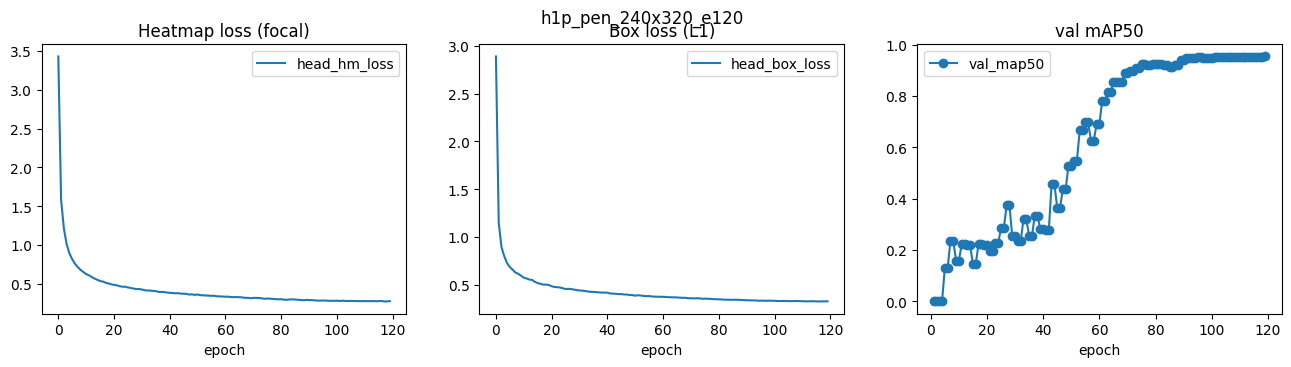

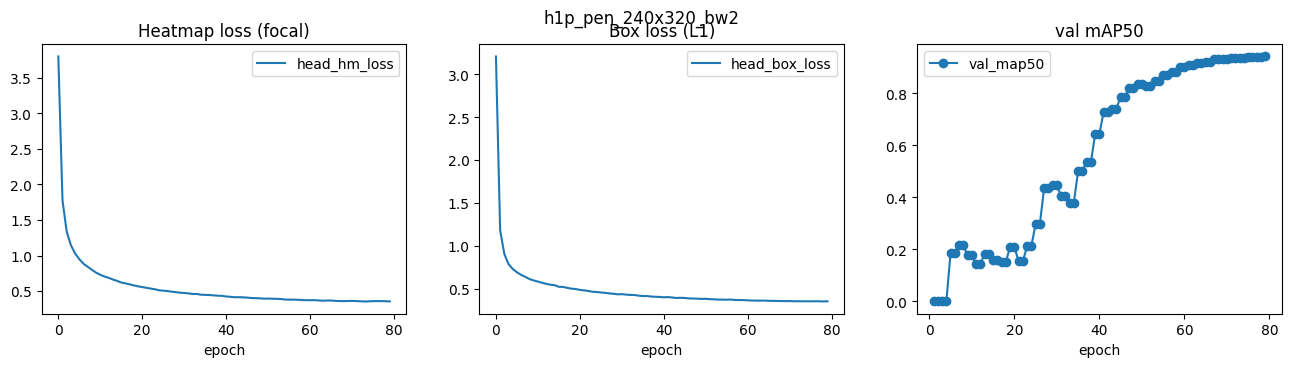

In [27]:
# Ô 4 – Đường cong loss / mAP val của các thí nghiệm trong hàng đợi
import json, os
import pandas as pd, matplotlib.pyplot as plt
for name in json.load(open('configs/queue.json'))['queue']:
    p = f'{DRIVE}/experiments/{name}/log.csv'
    if not os.path.exists(p):
        continue
    log = pd.read_csv(p)
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.5)); fig.suptitle(name)
    log.plot(x='epoch', y='head_hm_loss', ax=ax[0], title='Heatmap loss (focal)')
    log.plot(x='epoch', y='head_box_loss', ax=ax[1], title='Box loss (L1)')
    log.dropna(subset=['val_map50']).plot(x='epoch', y='val_map50', ax=ax[2], marker='o', title='val mAP50')
    plt.show()